# 01 · Análise Exploratória (EDA)

**Perguntas do desafio**
1. Qual o perfil geral dos dados? Distribuições, faltantes, outliers: como tratar cada caso?
2. Quais atributos do criativo mais se correlacionam com boas métricas de performance?
3. Existem padrões diferentes por plataforma? O que funciona no TikTok funciona no LinkedIn?
4. Visualizações para apresentar insights a um time de marketing.

Decisões de limpeza estão implementadas em `src/klike/data.py` e justificadas em `docs/decisions.md`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

from klike.data import load_raw, load_clean, PLATFORMS, CREATIVE, CONTEXT, PERFORMANCE, REVENUE_OBJECTIVES
from klike.analysis import boolean_lift_table, adjusted_log_effects, METRIC_LABELS
from klike.paths import FIGURES_EDA

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"Meta": "#4C72B0", "TikTok": "#DD8452", "LinkedIn": "#55A868"}

raw = load_raw()
df = load_clean()
raw.shape, df.shape

((500, 26), (500, 39))

## 1. Perfil geral dos dados

In [2]:
print(f"{len(raw)} campanhas · {raw['date'].min():%d/%m/%Y} a {raw['date'].max():%d/%m/%Y} · IDs únicos: {raw['campaign_id'].is_unique}")
pd.DataFrame({
    "plataforma": raw["platform"].value_counts(),
}).T

500 campanhas · 01/01/2024 a 30/12/2024 · IDs únicos: True


platform,Meta,TikTok,LinkedIn
plataforma,241,176,83


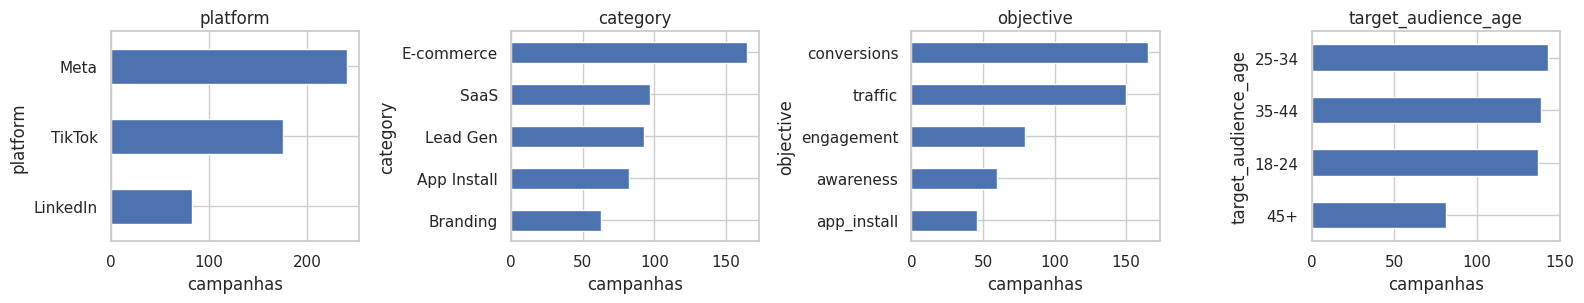

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, col in zip(axes, ["platform", "category", "objective", "target_audience_age"]):
    raw[col].value_counts().sort_values().plot.barh(ax=ax, color="#4C72B0")
    ax.set_title(col); ax.set_xlabel("campanhas")
plt.tight_layout()

**📊 Como ler:** cada painel conta quantas campanhas existem em cada valor de uma variável de contexto.

**O que o gráfico mostra**
- **Plataforma:** Meta 241, TikTok 176, LinkedIn 83. O LinkedIn tem 1/3 do volume do Meta.
- **Categoria:** E-commerce domina (165, 33%); Branding é a menor (63).
- **Objetivo:** conversions (165) e traffic (150) somam 63% das campanhas; app_install é o menor (46).
- **Faixa etária:** equilibrada entre 18–44 (~140 cada), com 45+ sub-representado (81).

**💡 Takeaway:** a base é desequilibrada. Médias globais são puxadas por Meta, E-commerce e campanhas de conversão. Por isso as análises são feitas **por plataforma**, e resultados de segmentos pequenos (LinkedIn, 45+, app_install) vêm com mais incerteza.

A amostra é **desbalanceada por plataforma**: Meta tem 241 campanhas, TikTok 176 e LinkedIn só 83. Qualquer conclusão específica do LinkedIn tem intervalos de confiança mais largos. A engine de recomendações vai precisar levar isso em conta, com fallback para estimativas globais quando o segmento for pequeno.

### 1.1 Valores faltantes

In [4]:
miss = raw.isna().sum()
miss = miss[miss > 0].sort_values(ascending=False)
miss_tbl = pd.DataFrame({"faltantes": miss, "%": (miss / len(raw) * 100).round(1)})
miss_by_platform = raw.groupby("platform")[miss.index.tolist()].apply(lambda g: g.isna().mean() * 100).round(1).T
miss_tbl.join(miss_by_platform.add_prefix("% "))

,faltantes,%,% LinkedIn,% Meta,% TikTok
has_subtitle,46,9.2,10.8,8.7,9.1
video_duration_s,39,7.8,8.4,7.1,8.5
music_voice_ratio,38,7.6,13.3,6.2,6.8
engagement_rate,32,6.4,6.0,7.1,5.7
cpc,28,5.6,6.0,4.6,6.8
avg_watch_time_s,27,5.4,2.4,5.0,7.4
revenue,25,5.0,4.8,5.0,5.1


In [5]:
# A ausência está associada ao klike_score? (se sim, não seria MCAR)
rows = []
for col in miss.index:
    m = raw[col].isna()
    rows.append({"coluna": col, "score médio c/ faltante": raw.loc[m, "klike_score"].mean(),
                 "score médio s/ faltante": raw.loc[~m, "klike_score"].mean()})
pd.DataFrame(rows).set_index("coluna").round(1)

,score médio c/ faltante,score médio s/ faltante
coluna,,
has_subtitle,60.1,60.2
video_duration_s,62.0,60.0
music_voice_ratio,61.4,60.1
engagement_rate,63.2,59.9
cpc,64.1,59.9
avg_watch_time_s,60.6,60.1
revenue,54.4,60.5


**Tratamento por tipo de faltante**

| Coluna | Natureza | Tratamento |
|---|---|---|
| `cpc`, `revenue` | **Redundantes**: dá para derivar de `spend/clicks` e `roas × spend`, sempre presentes | Recalculadas |
| `has_subtitle`, `video_duration_s`, `music_voice_ratio` | Atributos do criativo não registrados | Ficam `NaN` + flag `*_missing`. O modelo (HistGradientBoosting) trata NaN nativamente |
| `engagement_rate`, `avg_watch_time_s` | Métricas de resultado não registradas | Ficam `NaN`; cada análise usa as linhas disponíveis |

As taxas de ausência são parecidas entre plataformas (~2–13%; o `music_voice_ratio` no LinkedIn, com 13%, é o maior). O score médio de quem tem faltante fica a ±2–4 pts de quem não tem, o que é compatível com ausência aleatória. A exceção é `revenue` (−6 pts, n=25), mas ela é reconstruída a partir de `roas × spend`, então não perdemos essas linhas. **Não imputei na base de análise**, porque imputar pela mediana achata distribuições e cria falsas associações na EDA.

### 1.2 Distribuições

In [6]:
num = ["video_duration_s", "music_voice_ratio", "impressions", "clicks", "ctr", "cpc", "spend",
       "conversions", "revenue", "roas", "avg_watch_time_s", "engagement_rate", "klike_score"]
raw[num].describe(percentiles=[.01, .25, .5, .75, .99]).T.round(3)

,count,mean,std,min,1%,25%,50%,75%,99%,max
video_duration_s,461.0,19.393,13.529,5.000,5.000,11.000,16.000,25.000,69.600,115.00
music_voice_ratio,462.0,0.400,0.203,0.020,0.046,0.230,0.385,0.550,0.864,0.92
impressions,500.0,153738.524,1171735.612,1000.000,1570.780,9986.000,23241.000,55172.750,909955.560,14052761.00
clicks,500.0,3594.104,7018.213,4.000,31.950,461.750,1351.000,3583.250,35176.000,72545.00
ctr,500.0,0.071,0.045,0.002,0.006,0.033,0.063,0.105,0.150,0.15
cpc,472.0,1.113,1.956,0.050,0.204,0.530,0.710,1.020,3.789,26.05
spend,500.0,4213.152,11573.976,2.960,22.225,313.452,1031.000,2867.953,57426.858,121226.10
conversions,500.0,131.352,314.565,0.000,0.000,10.000,34.500,111.000,1437.560,3666.00
revenue,475.0,6367.937,19267.181,0.000,0.000,262.175,1201.050,4189.025,66666.730,241597.29
roas,500.0,2.499,3.592,0.000,0.000,0.430,1.490,3.250,16.541,39.92


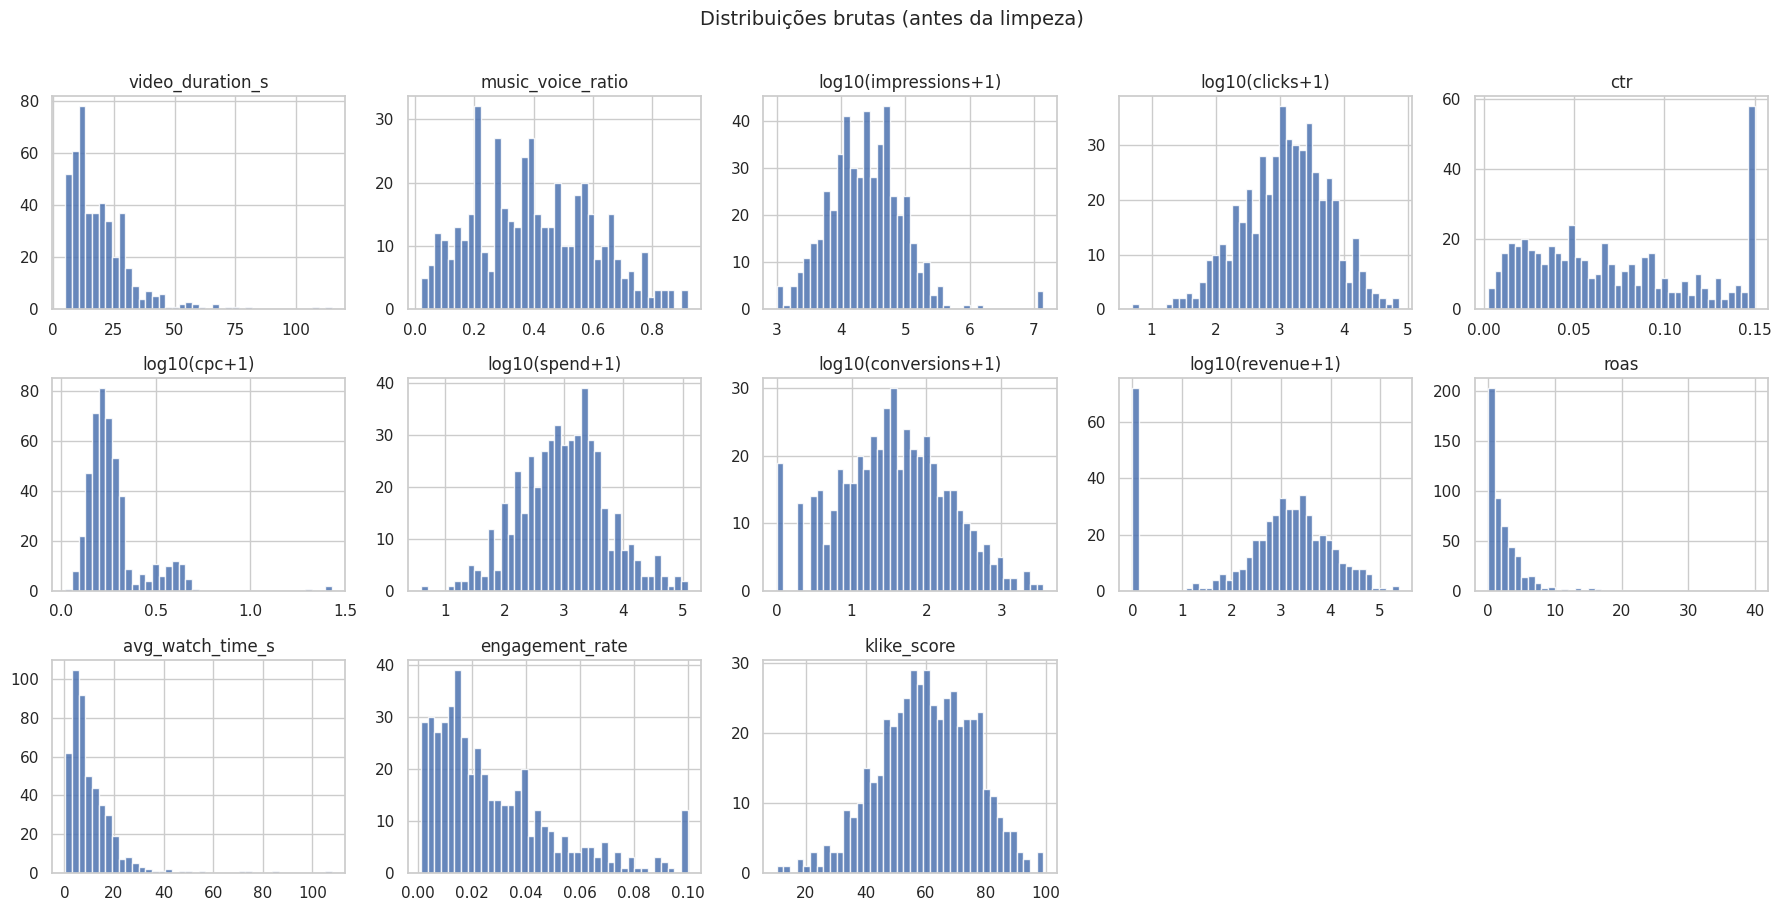

In [7]:
fig, axes = plt.subplots(3, 5, figsize=(18, 9))
log_cols = {"impressions", "clicks", "spend", "conversions", "revenue", "cpc"}
for ax, col in zip(axes.flat, num):
    s = raw[col].dropna()
    if col in log_cols:
        s = np.log10(s + 1); ax.set_title(f"log10({col}+1)")
    else:
        ax.set_title(col)
    ax.hist(s, bins=40, color="#4C72B0", alpha=.85)
for ax in axes.flat[len(num):]:
    ax.axis("off")
plt.suptitle("Distribuições brutas (antes da limpeza)", y=1.01, fontsize=14)
plt.tight_layout()

**📊 Como ler:** histograma de cada variável numérica **antes da limpeza**. Volumes (impressões, cliques, spend, conversões, receita, CPC) estão em escala log10, porque variam de unidades a milhões.

**O que o gráfico mostra**
- **Volumes em log viram sinos razoavelmente simétricos**, ou seja, têm distribuição aproximadamente log-normal: muitas campanhas pequenas e poucas muito grandes.
- **Impressões**: há pontos isolados na extrema direita. São as 4 campanhas com 12–14M (investigadas em 1.3).
- **CTR**: barra isolada em 0,15 (55 campanhas no teto). **Engajamento**: o mesmo em 0,10 (11 campanhas). É um corte artificial dos dados.
- **ROAS**: pico em zero (76 campanhas, quase todas de awareness/engagement) e cauda longa até 40.
- **Duração**: concentrada entre 11 e 25s (mediana 16s), com cauda até 115s.
- **Klike Score**: formato de sino centrado em ~60 (desvio 15,6), cobrindo de 10 a 99.

**💡 Takeaway:** volumes devem ser analisados em log ou por taxas, nunca em média simples. Os tetos de CTR e engajamento fazem **medianas** serem mais confiáveis que médias. O score já está bem comportado e pode ser modelado sem transformação.

- **Volumes** (impressões, cliques, spend, conversões, receita) têm cauda longa de várias ordens de grandeza, então são analisados em escala log.
- **CTR tem um pico em 0,15** (55 campanhas exatamente no teto) e o **engagement em 0,10** (11 campanhas): é clipping da geração dos dados. Por isso uso **medianas**, mais robustas a esse teto que médias.
- **`klike_score`** é aproximadamente normal (média 60, desvio 15,6) e cobre de 10 a 99. É um bom alvo de regressão, sem precisar de transformação.

### 1.3 Outliers e inconsistências

In [8]:
chk = raw.assign(
    ctr_calc=raw["clicks"] / raw["impressions"],
    cpc_calc=raw["spend"] / raw["clicks"],
)
bad_ctr = (chk["ctr_calc"] - chk["ctr"]).abs() > 0.002
bad_cpc = chk["cpc"].notna() & ((chk["cpc_calc"] - chk["cpc"]).abs() > 0.05)
print(f"CTR incoerente com clicks/impressions: {bad_ctr.sum()} linhas")
print(f"CPC incoerente com spend/clicks:      {bad_cpc.sum()} linhas")
chk.loc[bad_ctr | bad_cpc, ["campaign_id", "platform", "impressions", "clicks", "ctr", "ctr_calc",
                            "spend", "cpc", "cpc_calc", "revenue", "roas"]].round(4)

CTR incoerente com clicks/impressions: 4 linhas
CPC incoerente com spend/clicks:      6 linhas


,campaign_id,platform,impressions,clicks,ctr,ctr_calc,spend,cpc,cpc_calc,revenue,roas
99,KLK-0100,Meta,13342,951,0.0713,0.0713,370.89,20.00,0.3900,1162.54,3.13
108,KLK-0109,Meta,3701,205,0.0555,0.0554,50544.77,1.18,246.5599,63.87,0.26
147,KLK-0148,TikTok,13007321,629,0.0148,0.0000,339.66,0.54,0.5400,0.00,0.00
223,KLK-0224,Meta,117801,17670,0.1500,0.1500,85023.80,1.22,4.8118,0.00,0.00
231,KLK-0232,TikTok,12594257,345,0.0295,0.0000,162.15,0.47,0.4700,77.59,0.48
239,KLK-0240,Meta,135857,2825,0.0208,0.0208,2768.50,24.17,0.9800,11936.58,4.31
257,KLK-0258,TikTok,12873562,3704,0.0426,0.0003,2037.20,0.55,0.5500,668.83,0.33
258,KLK-0259,TikTok,1252,20,0.0161,0.0160,95811.69,0.27,4790.5845,72.62,13.45
412,KLK-0413,LinkedIn,14052761,2695,0.0374,0.0002,9243.85,3.43,3.4300,2227.32,0.24
415,KLK-0416,Meta,32532,1538,0.0473,0.0473,1138.12,26.05,0.7400,2510.55,2.21


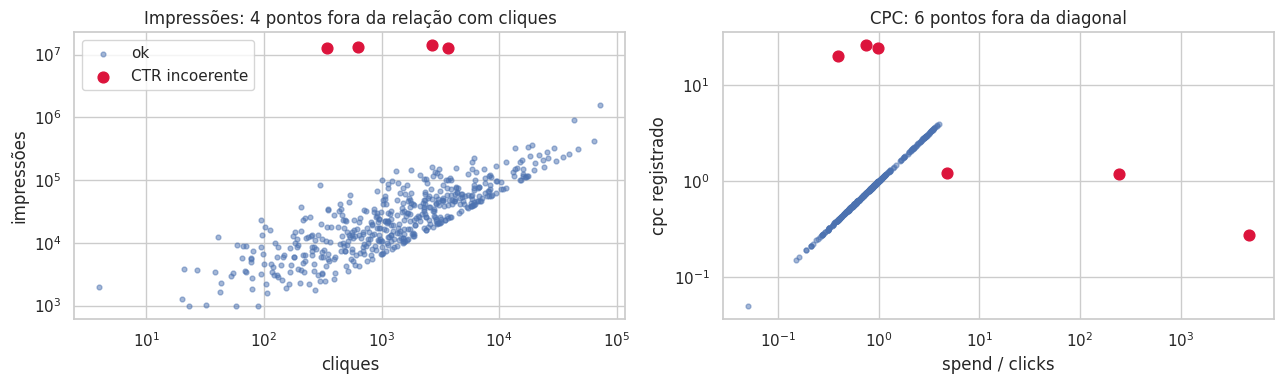

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.scatter(raw["clicks"], raw["impressions"], s=12, alpha=.5, label="ok")
ax.scatter(raw.loc[bad_ctr, "clicks"], raw.loc[bad_ctr, "impressions"], s=60, color="crimson", label="CTR incoerente")
ax.set(xscale="log", yscale="log", xlabel="cliques", ylabel="impressões", title="Impressões: 4 pontos fora da relação com cliques")
ax.legend()
ax = axes[1]
ax.scatter(chk["cpc_calc"], chk["cpc"], s=12, alpha=.5)
ax.scatter(chk.loc[bad_cpc, "cpc_calc"], chk.loc[bad_cpc, "cpc"], s=60, color="crimson")
ax.set(xscale="log", yscale="log", xlabel="spend / clicks", ylabel="cpc registrado", title="CPC: 6 pontos fora da diagonal")
plt.tight_layout()

**📊 Como ler**
- **Esquerda:** cada ponto é uma campanha. Como CTR = cliques ÷ impressões, campanhas coerentes formam uma faixa diagonal: mais cliques, mais impressões.
- **Direita:** CPC registrado (eixo y) contra CPC calculado como spend ÷ cliques (eixo x). Se os dados são coerentes, os pontos caem **exatamente na diagonal**.

**O que o gráfico mostra**
- **Esquerda:** 4 pontos vermelhos muito acima da faixa, com 12–14M de impressões para poucas centenas ou milhares de cliques. Se fossem reais, o CTR seria ~0,005%, mas o registrado é 1,5–4,3%.
- **Direita:** 6 pontos fora da diagonal.
  - 3 à direita/abaixo: **spend inflado**, em que o CPC calculado (R$ 5 a R$ 4.790) é muito maior que o registrado.
  - 3 acima: **CPC inflado**, registrado em R$ 20–26 enquanto spend ÷ cliques dá menos de R$ 1.

**💡 Takeaway:** os pontos foram identificados por **incoerência** entre colunas que deveriam bater por definição, não por serem grandes. As outras 490 campanhas caem exatamente sobre as relações esperadas.

**Diagnóstico.** Esses pontos não são outliers legítimos, são **erros de registro**: em cada linha, um campo isolado está inflado e os demais são coerentes entre si.

| Caso | Evidência | Correção |
|---|---|---|
| 4 campanhas com 12–14M impressões | Cliques, spend e CPC batem entre si. Com 12–14M impressões, o custo por mil impressões (CPM) seria de R$ 0,01–0,66, contra mínimo de R$ 1,31 nas outras 496 campanhas. Recalculadas, as impressões dão CPMs normais (R$ 8–128) | `impressions = clicks / ctr` |
| 3 campanhas com spend inflado (KLK-0109, 0224, 0259) | Em 0109 e 0259, `revenue / roas` reproduz exatamente `cpc × clicks`. O 0224 tem receita zero e não permite essa checagem | `spend = cpc × clicks` |
| 3 campanhas com CPC de R$ 20–26 (KLK-0100, 0240, 0416) | Mediana do CPC é R$ 0,82; `spend/clicks` dá R$ 0,39–0,98; e `revenue / spend` reproduz exatamente o ROAS registrado, então o spend está certo | `cpc = spend / clicks` |

Regra geral: **corrijo o campo que contradiz os demais**. Em todos os casos, ele era o maior dos dois valores conflitantes. Uma terceira coluna, o ROAS, confirma qual campo está errado em **5 dos 6** casos de spend/CPC; o sexto (KLK-0224) tem receita zero e não permite a checagem.

Os demais valores extremos (spend de R$ 121k, ROAS de 40, vídeos de 115s) são coerentes com as outras colunas, então são **campanhas reais grandes ou excepcionais**. Eles ficam na base. Para análise, uso log ou medianas; para os gráficos, recorte no p99.

In [10]:
print("Linhas corrigidas por load_clean():")
print(df["data_issue"].replace("", "—").value_counts().to_string())
fixed = (df["clicks"] / df["impressions"] - df["ctr"]).abs().gt(0.002).sum(), (df["spend"] / df["clicks"] - df["cpc"]).abs().gt(0.05).sum()
print(f"\nInconsistências restantes · CTR: {fixed[0]} · CPC: {fixed[1]}")

Linhas corrigidas por load_clean():
data_issue
—                    490
impressions_fixed      4
cpc_fixed              3
spend_fixed            3

Inconsistências restantes · CTR: 0 · CPC: 0


### 1.4 Zeros estruturais

In [11]:
df.groupby("objective").agg(campanhas=("roas", "size"), pct_receita_zero=("revenue", lambda s: (s == 0).mean() * 100),
                            roas_mediano=("roas", "median")).round(1)

,campanhas,pct_receita_zero,roas_mediano
objective,,,
app_install,46,0.0,0.6
awareness,60,58.3,0.0
conversions,165,2.4,2.3
engagement,79,40.5,0.9
traffic,150,3.3,1.6


Receita zero é **esperada** em awareness/engagement (não são campanhas de venda), não é dado faltante. Por isso **ROAS só é analisado nos objetivos traffic, conversions e app_install**. Misturar tudo faria parecer que atributos comuns em campanhas de awareness "derrubam" o ROAS.

> 📌 **Conclusões da seção 1:**
>    - **A base é pequena (500)** mas limpa depois de corrigir 10 linhas com erros de registro. 
>    - Os faltantes **não** parecem enviesados. 
>    - **Pontos de atenção**: plataformas desbalanceadas (LinkedIn n=83), tetos artificiais no CTR e no engagement, e receita zero estrutural.

## 2. Quais atributos do criativo se associam a boa performance?

Métricas de performance analisadas, normalizadas para comparar campanhas de tamanhos diferentes:

| Métrica | O que mede |
|---|---|
| **CTR** | o criativo gera clique? |
| **Engajamento** | gera interação (likes, comentários, shares)? |
| **Retenção** (`avg_watch_time / duração`) | prende a atenção? |
| **Taxa de conversão** (`conversões / cliques`) | o clique vira resultado? |
| **ROAS** | retorno financeiro (só objetivos de receita) |
| **Klike Score** | qualidade geral atribuída pelo Klike |

Para atributos sim/não, comparo a **mediana com o atributo vs sem ele**, com intervalo de confiança bootstrap de 90%.

In [12]:
BOOL_ATTRS = ["has_hook", "has_face", "has_cta", "has_subtitle"]
METRICS = ["ctr", "engagement_rate", "watch_ratio", "conversion_rate", "klike_score"]

lift_all = boolean_lift_table(df, BOOL_ATTRS, METRICS)
roas_lift = boolean_lift_table(df[df["has_revenue_objective"]], BOOL_ATTRS, ["roas"])
lift_all = pd.concat([lift_all, roas_lift])

def fmt(r):
    return f"{r.lift:+.0%} [{r.ci_low:+.0%}, {r.ci_high:+.0%}]"

tbl = lift_all.assign(txt=lift_all.apply(fmt, axis=1)).pivot(index="attribute", columns="metric", values="txt")
tbl[METRICS + ["roas"]].rename(columns=METRIC_LABELS)

metric,CTR,Engajamento,Retenção (watch ratio),Taxa de conversão,Klike Score,ROAS
attribute,,,,,,
has_cta,"+14% [-11%, +39%]","+9% [-13%, +33%]","-2% [-11%, +8%]","-3% [-14%, +19%]","+13% [+8%, +23%]","+1% [-24%, +26%]"
has_face,"+37% [+19%, +63%]","+55% [+23%, +86%]","+16% [+4%, +26%]","+8% [-8%, +21%]","+21% [+15%, +27%]","-3% [-29%, +22%]"
has_hook,"+68% [+43%, +90%]","+37% [+10%, +63%]","+34% [+23%, +50%]","+3% [-12%, +16%]","+33% [+29%, +38%]","-21% [-42%, -3%]"
has_subtitle,"+15% [-4%, +33%]","+2% [-16%, +30%]","+3% [-5%, +15%]","-7% [-15%, +14%]","+10% [+5%, +20%]","-7% [-27%, +22%]"


**📐 Como ler os intervalos: o que é o bootstrap**

Cada célula mostra **lift observado [intervalo de confiança de 90%]**. O lift vem de 500 campanhas; com outra amostra, o número seria um pouco diferente. O intervalo indica quanto ele poderia variar.

Para calculá-lo uso o **bootstrap**, que simula "outras amostras" a partir da própria base:
1. sortear, **com reposição**, o mesmo número de campanhas de cada grupo (com e sem o atributo);
2. recalcular as medianas e o lift nessa amostra sorteada;
3. repetir **1.000 vezes** e pegar os percentis 5% e 95% dos 1.000 lifts.

**Exemplos desta tabela**
- **Hook → CTR: +68% [+43%, +90%].** O intervalo inteiro é positivo, então o efeito é **sólido**. O valor exato é incerto, mas a direção não.
- **CTA → CTR: +14% [−11%, +39%].** O intervalo **cruza o zero**, então não dá para distinguir de ruído. Por isso CTA e legenda são tratados como efeitos de segunda ordem.

**Por que bootstrap e não um teste t?** O teste t e as fórmulas clássicas são feitos para **médias** e supõem dados com distribuição normal. Aqui comparo uma **razão de medianas** em métricas com cauda longa e teto (CTR em 0,15), e para isso não há fórmula simples. O bootstrap funciona com qualquer estatística e não supõe formato de distribuição.

**Ressalvas**
- Com grupos muito pequenos (ex.: 11 vídeos verticais no LinkedIn), o bootstrap fica pouco confiável.
- O intervalo mede **incerteza amostral, não causalidade**. A checagem de confounding está na seção 2.2.
- Usei 90% em vez dos 95% tradicionais. Conferi o impacto: em **23 das 24** combinações desta tabela, a conclusão é a mesma com 95%. A exceção é **hook → ROAS (−21%)**, significativo a 90% mas não a 95%. É justamente o efeito que a seção 2.2 mostra ser **confounding** (≈ −2% depois de ajustar pelo contexto, principalmente pela plataforma), ou seja, um sinal fraco que não deve virar recomendação.

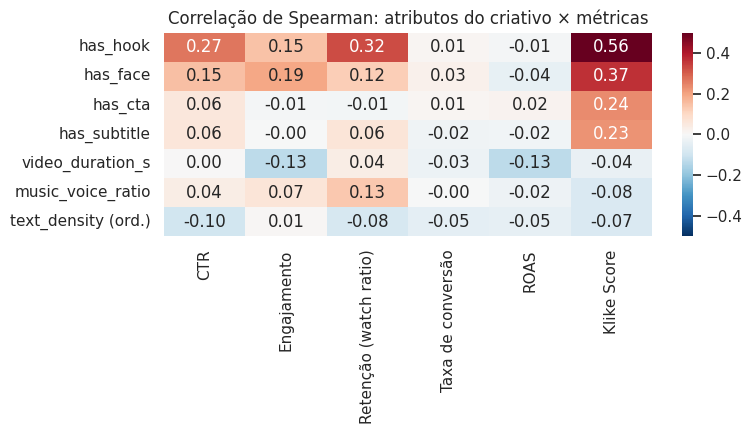

In [13]:
# Correlações de Spearman (robusta a outliers e relações não lineares)
corr_cols = ["has_hook", "has_face", "has_cta", "has_subtitle", "video_duration_s", "music_voice_ratio",
             "ctr", "engagement_rate", "watch_ratio", "conversion_rate", "roas", "klike_score"]
td = df["text_density"].map({"low": 0, "medium": 1, "high": 2}).rename("text_density (ord.)")
corr = pd.concat([df[corr_cols].astype(float), td], axis=1).corr(method="spearman")
attrs_c = ["has_hook", "has_face", "has_cta", "has_subtitle", "video_duration_s", "music_voice_ratio", "text_density (ord.)"]
mets_c = ["ctr", "engagement_rate", "watch_ratio", "conversion_rate", "roas", "klike_score"]
plt.figure(figsize=(8, 4.5))
sns.heatmap(corr.loc[attrs_c, mets_c].rename(columns=METRIC_LABELS), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-.5, vmax=.5)
plt.title("Correlação de Spearman: atributos do criativo × métricas")
plt.tight_layout()

**📊 Como ler:** cada célula é a correlação de Spearman entre um atributo do criativo (linha) e uma métrica (coluna). Vai de −1 a +1; vermelho é positivo e azul, negativo. Como referência: |ρ| ≈ 0,1 é fraco, 0,3 moderado e 0,5 forte. O Spearman usa a **ordem** dos valores, então é robusto a outliers e capta relações monotônicas, mesmo não lineares.

**O que o gráfico mostra**
- **Hook** tem as maiores correlações da tabela: **0,56** com o Klike Score, 0,32 com retenção e 0,27 com CTR.
- **Rosto** vem em segundo: 0,37 com o score, 0,19 com engajamento e 0,15 com CTR.
- **CTA e legenda** se correlacionam com o score (~0,24) mas quase nada com as métricas observadas (|ρ| ≤ 0,06).
- **Duração, proporção música/voz e densidade de texto** ficam perto de zero em tudo (|ρ| ≤ 0,13).
- As colunas de **conversão e ROAS** são praticamente zeradas: nenhum atributo do criativo se correlaciona com elas.

**⚠️ Limitação:** a densidade de texto aparece com ρ ≈ −0,07 com o score, mas ela **importa**: "medium" é bem melhor que "low" e "high". O efeito tem formato de U invertido, que o Spearman não capta porque só mede relações que sempre sobem ou sempre descem. Por isso ela é analisada à parte na seção 2.1 e na Fig 3.

**💡 Takeaway:** hook e rosto são as principais alavancas. O criativo influencia o **topo do funil** (atenção, clique, interação), não o fundo (conversão, ROAS), que depende mais de oferta, público e retargeting. O fato de CTA e legenda pesarem no score sem mexer nas métricas sugere que **o Klike Score valoriza essas boas práticas por si só**, o que é um ponto a investigar na modelagem.

### 2.1 Atributos categóricos: formato e densidade de texto

In [14]:
for attr in ["text_density", "format"]:
    display(df.groupby(attr)[METRICS].median().rename(columns=METRIC_LABELS).round(3))

,CTR,Engajamento,Retenção (watch ratio),Taxa de conversão,Klike Score
text_density,,,,,
high,0.043,0.018,0.459,0.027,49.8
low,0.067,0.021,0.508,0.031,58.6
medium,0.065,0.022,0.540,0.032,66.1


,CTR,Engajamento,Retenção (watch ratio),Taxa de conversão,Klike Score
format,,,,,
horizontal,0.066,0.016,0.545,0.030,58.30
quadrado,0.067,0.018,0.507,0.032,60.15
vertical,0.056,0.027,0.500,0.029,61.70


### 2.2 Isso não é só efeito de mix?

Se as campanhas com hook fossem, por exemplo, mais frequentes no TikTok ou em retargeting, o lift bruto confundiria o efeito do hook com o efeito do contexto. Para checar, faço uma **regressão em log(métrica)** com todos os atributos e o contexto (plataforma, objetivo, categoria, formato, densidade de texto, idade) como controles. O coeficiente vira um "efeito %" ajustado.

In [15]:
controls = ["platform", "objective", "category", "format", "text_density", "target_audience_age"]
adj_attrs = ["has_hook", "has_face", "has_cta", "is_retargeting"]
adj = pd.concat([adjusted_log_effects(df, m, adj_attrs, controls) for m in ["ctr", "engagement_rate", "conversion_rate", "klike_score"]]
                + [adjusted_log_effects(df[df["has_revenue_objective"]], "roas", adj_attrs, controls)], axis=1)
raw_lift = lift_all[lift_all["attribute"].isin(adj_attrs) & lift_all["metric"].isin(adj.columns)].pivot(index="attribute", columns="metric", values="lift")
pd.concat({"bruto (medianas)": raw_lift[adj.columns], "ajustado (regressão)": adj}, axis=1).map(lambda v: f"{v:+.0%}" if pd.notna(v) else "")

bruto (medianas)                                                   ajustado (regressão)                                                  
metric                      ctr engagement_rate conversion_rate klike_score  roas                  ctr engagement_rate conversion_rate klike_score  roas
has_cta                    +14%             +9%             -3%        +13%   +1%                  +9%             +4%             -3%        +16%   +3%
has_face                   +37%            +55%             +8%        +21%   -3%                 +23%            +43%             +3%        +25%   +3%
has_hook                   +68%            +37%             +3%        +33%  -21%                 +49%            +38%             +1%        +34%   -2%
is_retargeting                                                                                    +62%            +15%            +93%         +9%  +97%

**Decompondo o caso hook × ROAS.** O bruto e o ajustado concordam para CTR, engajamento e score, mas divergem no ROAS. Para entender **o que** explica a diferença, adiciono os controles um a um e vejo o quanto o efeito encolhe.

In [16]:
rev = df[df["has_revenue_objective"]]
steps = [
    ("nenhum (bruto)", []),
    ("+ retargeting", ["is_retargeting"]),
    ("+ objetivo", ["is_retargeting", "objective"]),
    ("+ categoria", ["is_retargeting", "objective", "category"]),
    ("+ plataforma", ["is_retargeting", "objective", "category", "platform"]),
    ("+ formato, texto, idade", ["is_retargeting", "objective", "category", "platform", "format", "text_density", "target_audience_age"]),
]
rows = []
for label, ctrls in steps:
    attrs = ["has_hook"] + [c for c in ctrls if c == "is_retargeting"]
    cats = [c for c in ctrls if c != "is_retargeting"]
    rows.append({"controles": label, "efeito do hook no ROAS": adjusted_log_effects(rev, "roas", attrs, cats)["has_hook"]})
decomp = pd.DataFrame(rows).set_index("controles")
display(decomp.map("{:+.0%}".format))

rev.groupby("platform").agg(pct_com_hook=("has_hook", "mean"), roas_mediano=("roas", "median"), n=("roas", "size")).round(2)

,efeito do hook no ROAS
controles,
nenhum (bruto),-17%
+ retargeting,-14%
+ objetivo,-11%
+ categoria,-10%
+ plataforma,-4%
"+ formato, texto, idade",-2%


,pct_com_hook,roas_mediano,n
platform,,,
LinkedIn,0.54,0.53,63
Meta,0.53,1.65,172
TikTok,0.44,2.96,126


**Leitura.** O efeito de −17% vai encolhendo até ≈ −2% à medida que o contexto é controlado. O maior salto vem da **plataforma** (de −10% para −4%):
- o **LinkedIn** tem a maior proporção de campanhas com hook (54%) e o menor ROAS (0,53);
- o **TikTok** tem a menor proporção (44%) e o maior ROAS (2,96).

O retargeting contribui menos: há menos retargeting entre as campanhas com hook (18% contra 25%), e ele quase dobra o ROAS. Ou seja, as campanhas com hook estão concentradas em contextos de ROAS naturalmente baixo, e o hook em si não tem efeito no ROAS.

*Nota:* aqui o "bruto" é −17%, e não os −21% da tabela de medianas, porque a regressão compara médias em escala log (média geométrica). A direção e a conclusão são as mesmas.

> 📌 **Conclusões da seção 2**
> - **Hook nos 3 primeiros segundos é o atributo mais forte**: +50–70% de CTR (ajustado/bruto), ~+35% de engajamento e retenção, e Klike Score mediano de 70 contra 52 sem hook. O efeito se mantém quando controlo pelo contexto.
> - **Rosto humano** é o segundo: forte em engajamento (+43–55%) e relevante em CTR (+23–37%).
> - **Densidade de texto "high" é penalizada**: CTR ~35% menor e score ~16 pts abaixo de "medium". Entre "low" e "medium" o CTR é parecido, mas o score favorece "medium".
> - **CTA e legenda** têm efeitos menores e intervalos que cruzam o zero na maioria das métricas. São melhorias de segunda ordem.
> - **Duração e proporção música/voz** quase não se correlacionam com as métricas no agregado (|ρ| < 0,15). O efeito, se existe, depende da plataforma (seção 3).
> - **Retargeting** (contexto, não criativo) praticamente dobra a taxa de conversão. É um confounder importante, e por isso entra como controle.
> - Conversão e ROAS dependem pouco dos atributos do criativo: o criativo influencia mais o **topo do funil** (clique, atenção, interação) do que o fundo.
> - ⚠️ **Exemplo de confounding**: no bruto, campanhas com hook têm ROAS **21% menor**. Ajustando, o efeito é ≈ **−2%**, ou seja, nulo. A explicação é de **contexto**: as campanhas com hook estão concentradas em plataformas de ROAS baixo (LinkedIn, 54% com hook e ROAS 0,53, contra TikTok, 44% e ROAS 2,96) e têm menos retargeting (18% contra 25%), que quase dobra o ROAS. A plataforma é o maior confounder. Sem o ajuste, uma engine ingênua desaconselharia o hook para quem busca ROAS, o que seria um erro.

## 3. Padrões por plataforma: o que funciona no TikTok funciona no LinkedIn?

In [17]:
lift_pf = boolean_lift_table(df, BOOL_ATTRS, ["ctr", "engagement_rate", "watch_ratio", "klike_score"], by="platform")
lift_pf.pivot_table(index=["attribute", "segment"], columns="metric", values="lift").rename(columns=METRIC_LABELS).map(lambda v: f"{v:+.0%}")

metric                   CTR Engajamento Klike Score Retenção (watch ratio)
attribute    segment                                                       
has_cta      LinkedIn   +22%         +5%        +22%                   -15%
             Meta        -5%        +10%        +11%                    -9%
             TikTok     +15%        +10%        +16%                    -1%
has_face     LinkedIn   +62%        +10%        +21%                   +21%
             Meta        +6%        +54%        +24%                   +29%
             TikTok     +75%        +35%        +14%                    -4%
has_hook     LinkedIn  +119%         +5%        +27%                   +36%
             Meta       +57%        +43%        +34%                   +34%
             TikTok     +79%        +23%        +32%                   +34%
has_subtitle LinkedIn    +1%        +79%         +9%                    +4%
             Meta       +13%         -2%        +10%                    -4%
             TikTok     +22%        -16%        +12%                   +13%

In [18]:
pd.crosstab(df["platform"], df["format"]).rename_axis(index=None)

format,horizontal,quadrado,vertical
LinkedIn,44,28,11
Meta,67,68,106
TikTok,0,24,152


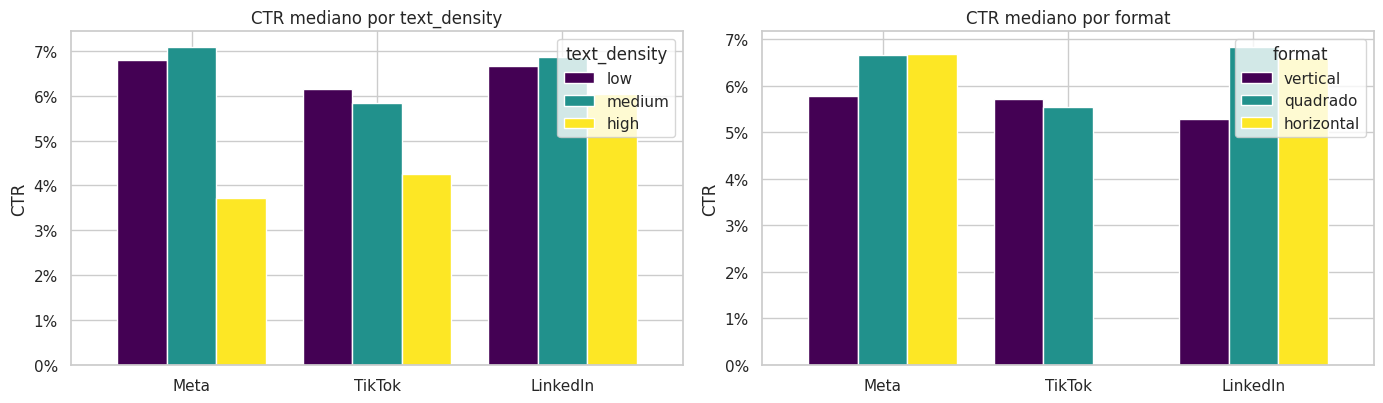

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, attr in zip(axes, ["text_density", "format"]):
    order = ["low", "medium", "high"] if attr == "text_density" else ["vertical", "quadrado", "horizontal"]
    d = df.groupby(["platform", attr])["ctr"].median().unstack().reindex(columns=order).loc[PLATFORMS]
    d.plot.bar(ax=ax, rot=0, colormap="viridis", width=.8)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
    ax.set(title=f"CTR mediano por {attr}", xlabel="", ylabel="CTR")
plt.tight_layout()

**📊 Como ler:** CTR mediano por plataforma. À esquerda, quebrado por densidade de texto; à direita, por formato do vídeo. Cada grupo de barras é uma plataforma.

**O que o gráfico mostra**
- **Densidade de texto:**
  - No **Meta**, "high" tem CTR de 3,7% contra 7,1% de "medium" (**−48%**).
  - No **TikTok**, "high" tem 4,3% contra ~6% de "low"/"medium".
  - No **LinkedIn**, a diferença é pequena (6,0% contra 6,9%).
- **Formato:**
  - No **LinkedIn**, o vertical tem o menor CTR (5,3%, contra 6,6–6,8%).
  - No **Meta**, o vertical também clica menos (5,8%, contra 6,7%). Em compensação, é o formato com **maior engajamento** no Meta.
  - No **TikTok**, vertical e quadrado são equivalentes em CTR, e não há campanhas horizontais.

**💡 Takeaway:** texto "high" é o fator negativo mais claro, principalmente no Meta. O formato vertical **não** é vantagem de CTR fora do TikTok. No LinkedIn e no Meta, horizontal e quadrado geram mais cliques.

### 3.1 Duração ideal por plataforma

In [20]:
bins = [0, 10, 15, 20, 30, 60, 200]
labels = ["≤10s", "11–15s", "16–20s", "21–30s", "31–60s", ">60s"]
df["duration_bin"] = pd.cut(df["video_duration_s"], bins=bins, labels=labels)
dur = df.groupby(["platform", "duration_bin"], observed=True).agg(
    n=("ctr", "size"), ctr=("ctr", "median"), retencao=("watch_ratio", "median"), score=("klike_score", "median"))
dur.round(3)

n    ctr  retencao  score
platform duration_bin                            
LinkedIn ≤10s           3  0.070     0.210  40.60
         11–15s        10  0.098     0.464  56.55
         16–20s        16  0.048     0.749  58.90
         21–30s        28  0.073     0.456  56.65
         31–60s        16  0.046     0.463  56.55
         >60s           3  0.068     0.707  64.60
Meta     ≤10s          48  0.066     0.533  61.35
         11–15s        57  0.080     0.550  63.70
         16–20s        32  0.063     0.459  57.30
         21–30s        55  0.067     0.560  60.00
         31–60s        27  0.048     0.514  57.40
         >60s           5  0.036     0.453  63.70
TikTok   ≤10s          62  0.056     0.500  62.85
         11–15s        48  0.046     0.473  55.65
         16–20s        21  0.082     0.482  62.30
         21–30s        25  0.092     0.579  65.80
         31–60s         5  0.027     0.402  66.80

In [21]:
df.groupby("platform")["video_duration_s"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
platform,,,,,,,,
LinkedIn,76.0,27.3,16.3,10.0,18.5,24.5,30.2,115.0
Meta,224.0,20.4,14.2,5.0,11.0,16.0,26.0,108.0
TikTok,161.0,14.3,7.9,5.0,9.0,13.0,18.0,53.0


### 3.2 Rosto humano × faixa etária

In [22]:
face_age = df.groupby(["target_audience_age", "has_face"])["engagement_rate"].median().unstack()
(face_age[True] / face_age[False] - 1).rename("lift de engajamento com rosto").map("{:+.0%}".format).to_frame()

,lift de engajamento com rosto
target_audience_age,
18-24,+64%
25-34,+68%
35-44,+29%
45+,+15%


> 📌 **Conclusões da seção 3. O que funciona no TikTok nem sempre funciona no LinkedIn.**
> - **O hook é universal**: é positivo em todas as plataformas, com o maior ganho de CTR no LinkedIn (~+120%). Num feed profissional, quem não prende nos 3s é ignorado.
> - **O papel do rosto muda com a plataforma**: no **TikTok** gera clique (+75% CTR); no **Meta** gera interação (+54% engajamento, CTR quase igual); no **LinkedIn** ajuda CTR e conversão.
> - **O formato é contextual**: no TikTok o vertical é nativo (152/176 campanhas; quadrado tem score ~13 pts menor). No **LinkedIn o vertical é o pior formato** (CTR e score mais baixos, ainda que com n=11), com horizontal e quadrado à frente. No Meta a diferença é pequena.
> - **Texto "high" pesa mais no Meta**: o CTR cai ~48% em relação a "medium". No TikTok a queda também existe (−27%), e no LinkedIn é menor (−12%).
> - **O efeito do rosto diminui com a idade do público**: +64–68% de engajamento para 18–34 anos contra só +15% para 45+.
> - **A legenda tem papel diferente**: no LinkedIn quase não altera o CTR mas eleva muito o engajamento, coerente com o consumo sem som em ambiente de trabalho.
> - **A duração tem sinal fraco e ruidoso** (n pequeno por faixa). As medianas sugerem pontos ótimos de **11–15s no Meta** e **16–30s no TikTok**, e vídeos >30s têm CTR menor no Meta e no TikTok. Isso deve ser tratado como hipótese a testar, não como regra.

## 4. Visualizações para o time de marketing

Cada gráfico tem um título que já entrega a mensagem. As figuras são salvas em `reports/figures/eda/` e usadas no README.

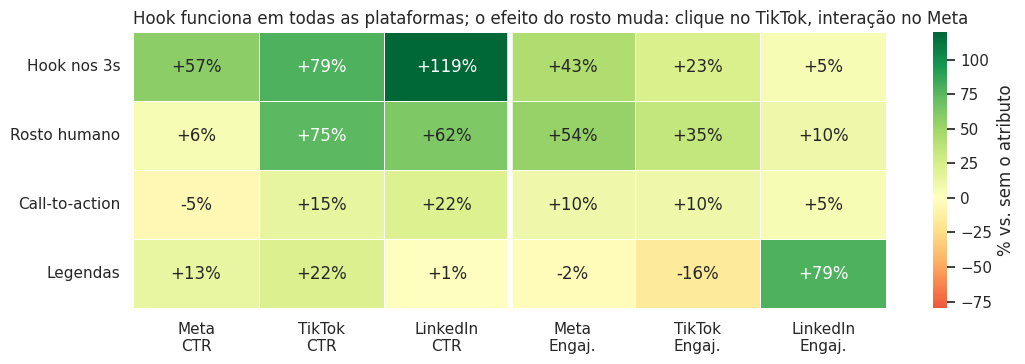

In [23]:
# Fig 1: mapa de calor de lift por plataforma
heat = (lift_pf[lift_pf["metric"].isin(["ctr", "engagement_rate"])]
        .assign(col=lambda d: d["segment"] + " · " + d["metric"].map({"ctr": "CTR", "engagement_rate": "Engaj."}))
        .pivot(index="attribute", columns="col", values="lift"))
heat = heat[[f"{p} · {m}" for m in ["CTR", "Engaj."] for p in PLATFORMS]]
heat.columns = [c.replace(" · ", "\n") for c in heat.columns]
heat.index = heat.index.map({"has_hook": "Hook nos 3s", "has_face": "Rosto humano", "has_cta": "Call-to-action", "has_subtitle": "Legendas"})
heat = heat.loc[["Hook nos 3s", "Rosto humano", "Call-to-action", "Legendas"]]

fig, ax = plt.subplots(figsize=(11, 3.8))
sns.heatmap(heat * 100, annot=heat.map(lambda v: f"{v:+.0%}"), fmt="", cmap="RdYlGn", center=0, vmin=-80, vmax=120,
            cbar_kws={"label": "% vs. sem o atributo"}, linewidths=.5, ax=ax)
ax.set(xlabel="", ylabel="")
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)
ax.axvline(3, color="white", lw=4)
ax.set_title("Hook funciona em todas as plataformas; o efeito do rosto muda: clique no TikTok, interação no Meta", fontsize=12, loc="left")
plt.tight_layout()
fig.savefig(FIGURES_EDA / "01_lift_por_plataforma.png", dpi=150, bbox_inches="tight")

**📊 Como ler:** cada célula mostra quanto a métrica mediana muda (%) nas campanhas **com** o atributo em relação às campanhas **sem** ele, dentro da mesma plataforma. As 3 colunas da esquerda são CTR e as 3 da direita, engajamento. Verde significa que o atributo ajuda e vermelho, que atrapalha.

**O que o gráfico mostra**
- **Hook:** a única linha verde em todas as células. No CTR, +57% (Meta), +79% (TikTok) e **+119% (LinkedIn)**.
- **Rosto:** o efeito depende da plataforma.
  - **TikTok:** +75% de CTR.
  - **LinkedIn:** +62% de CTR.
  - **Meta:** só +6% de CTR, mas **+54% de engajamento**.
- **CTA:** efeitos pequenos em todas as plataformas (de −5% a +22%).
- **Legendas:**
  - **LinkedIn:** engajamento sobe **+79%**, mas o CTR não se altera.
  - **TikTok:** engajamento cai 16%.

**💡 Takeaway:** "adicione um hook" é uma recomendação **universal**. "Adicione um rosto" depende do objetivo: no TikTok e no LinkedIn gera clique, no Meta gera interação. Legendas valem a pena no LinkedIn, onde muita gente assiste sem som no trabalho, para quem busca engajamento. Ressalva: o LinkedIn tem n=83, então seus percentuais são os menos precisos.

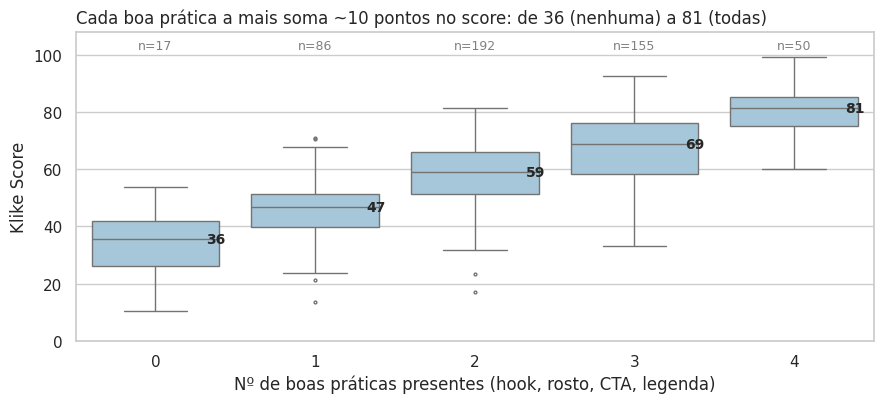

In [24]:
# Fig 2: escada de completude do criativo
df["n_elementos"] = df[["has_hook", "has_face", "has_cta"]].sum(axis=1) + df["has_subtitle"].fillna(False).astype(int)
ladder = df.groupby("n_elementos")["klike_score"].agg(["median", "size"])

fig, ax = plt.subplots(figsize=(9, 4.2))
sns.boxplot(data=df, x="n_elementos", y="klike_score", color="#9ecae1", fliersize=2, ax=ax)
for i, (k, r) in enumerate(ladder.iterrows()):
    ax.text(i, 102, f"n={int(r['size'])}", ha="center", fontsize=9, color="gray")
    ax.text(i + .32, r["median"], f"{r['median']:.0f}", va="center", fontsize=10, weight="bold")
ax.set(ylim=(0, 108), xlabel="Nº de boas práticas presentes (hook, rosto, CTA, legenda)", ylabel="Klike Score")
ax.set_title(f"Cada boa prática a mais soma ~10 pontos no score: de {ladder['median'].iloc[0]:.0f} (nenhuma) a {ladder['median'].iloc[-1]:.0f} (todas)", loc="left", fontsize=12)
plt.tight_layout()
fig.savefig(FIGURES_EDA / "02_escada_boas_praticas.png", dpi=150, bbox_inches="tight")

**📊 Como ler:** cada caixa mostra a distribuição do Klike Score das campanhas com 0, 1, 2, 3 ou 4 boas práticas (hook, rosto, CTA, legenda). A linha dentro da caixa é a mediana (número em negrito), a caixa contém os 50% centrais e as hastes, o restante. O n de cada grupo está no topo.

**O que o gráfico mostra**
- As medianas sobem de forma quase **linear**: **36 → 47 → 59 → 69 → 81**, cerca de +11 pontos por prática.
- Os extremos quase não se sobrepõem: sem nenhuma prática, o score máximo fica em ~54; com as quatro, o mínimo fica em ~60.
- Só 17 campanhas não têm nenhuma prática e 50 têm todas. A maioria está no meio (2–3).

**💡 Takeaway:** as boas práticas **se somam**, e essa é a mensagem mais simples para um time de marketing. O padrão tão regular também sugere que o Klike Score pode ter sido construído de forma aditiva, o que é uma pista para a modelagem. Ressalva: a contagem trata todas as práticas como iguais, mas a Fig 1 e as correlações mostram que o hook pesa mais que CTA e legenda.

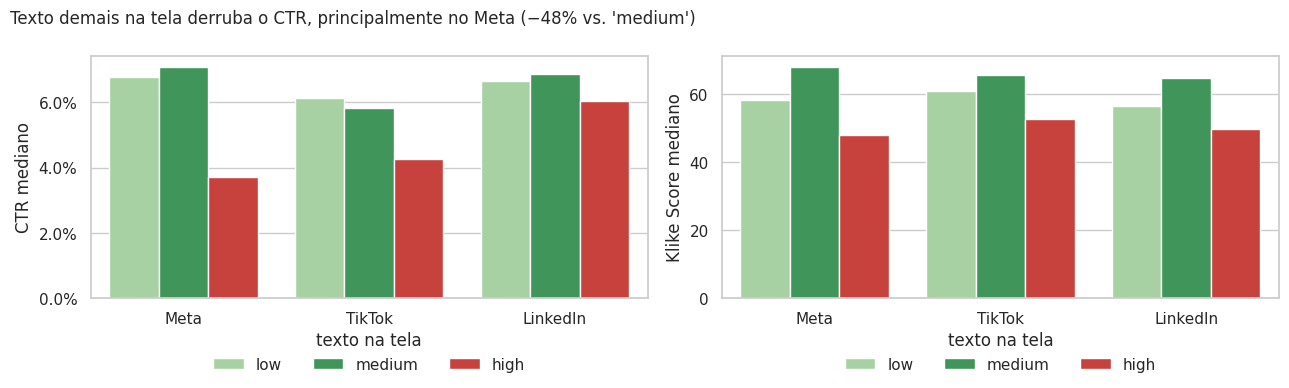

In [25]:
# Fig 3: densidade de texto por plataforma
td = df.groupby(["platform", "text_density"]).agg(ctr=("ctr", "median"), score=("klike_score", "median")).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (m, lab, f) in zip(axes, [("ctr", "CTR mediano", mtick.PercentFormatter(1, 1)), ("score", "Klike Score mediano", None)]):
    sns.barplot(data=td, x="platform", y=m, hue="text_density", hue_order=["low", "medium", "high"], order=PLATFORMS,
                palette=["#a1d99b", "#31a354", "#de2d26"], ax=ax)
    ax.set(xlabel="", ylabel=lab)
    if f: ax.yaxis.set_major_formatter(f)
    ax.legend(title="texto na tela", loc="upper center", bbox_to_anchor=(.5, -.08), ncol=3, frameon=False)
fig.suptitle("Texto demais na tela derruba o CTR, principalmente no Meta (−48% vs. 'medium')", x=.01, ha="left", fontsize=12)
plt.tight_layout()
fig.savefig(FIGURES_EDA / "03_densidade_texto.png", dpi=150, bbox_inches="tight")

**📊 Como ler:** CTR mediano (esquerda) e Klike Score mediano (direita) por plataforma e por quantidade de texto na tela. Verde-claro é "low", verde-escuro "medium" e vermelho "high".

**O que o gráfico mostra**
- **CTR:** "high" é o pior em todas as plataformas.
  - **Meta:** cai pela metade (3,7% contra 7,1%).
  - **TikTok:** −27%.
  - **LinkedIn:** só −12%.
- **Score:** "medium" é o melhor em **todas** as plataformas (Meta 68, TikTok 66, LinkedIn 65).
  - Contra "high" (48–53), a vantagem é de 13 a 20 pontos.
  - Contra "low", a vantagem é de 5 a 10 pontos.

**💡 Takeaway:** evite texto "high", especialmente no Meta. A relação não é "quanto menos texto, melhor": algum texto ("medium") supera pouco texto ("low"), provavelmente porque reforça a mensagem para quem assiste sem som. O ideal é o meio-termo.

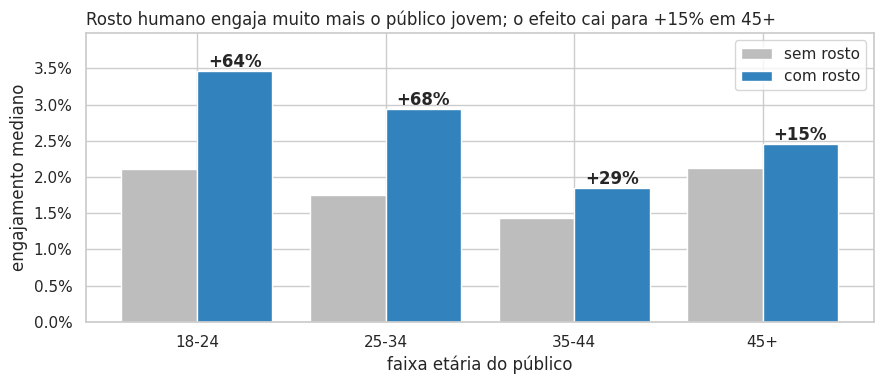

In [26]:
# Fig 4: rosto x faixa etária
fa = df.groupby(["target_audience_age", "has_face"])["engagement_rate"].median().unstack()
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(fa))
ax.bar(x - .2, fa[False], .4, label="sem rosto", color="#bdbdbd")
ax.bar(x + .2, fa[True], .4, label="com rosto", color="#3182bd")
for i, (a, b) in enumerate(zip(fa[False], fa[True])):
    ax.text(i + .2, b, f"{b / a - 1:+.0%}", ha="center", va="bottom", weight="bold")
ax.set_xticks(x, fa.index)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, 1))
ax.set(xlabel="faixa etária do público", ylabel="engajamento mediano")
ax.set_ylim(0, fa.to_numpy().max() * 1.15)
ax.legend()
ax.set_title("Rosto humano engaja muito mais o público jovem; o efeito cai para +15% em 45+", loc="left", fontsize=12)
plt.tight_layout()
fig.savefig(FIGURES_EDA / "04_rosto_por_idade.png", dpi=150, bbox_inches="tight")

**📊 Como ler:** engajamento mediano por faixa etária do público-alvo, comparando campanhas sem rosto (cinza) e com rosto (azul). O percentual acima da barra azul é o ganho com rosto.

**O que o gráfico mostra**
- **18–24:** de 2,1% para 3,5% (**+64%**).
- **25–34:** de 1,7% para 2,9% (**+68%**).
- **35–44:** de 1,4% para 1,9% (+29%).
- **45+:** de 2,1% para 2,5% (só **+15%**).
- Curiosidade: sem rosto, o público 45+ já engaja tanto quanto o de 18–24.

**💡 Takeaway:** incluir pessoas no vídeo é prioridade para públicos **de até 34 anos**. Para 45+, o ganho é pequeno, e outras alavancas (hook, texto, formato) devem vir antes. Na engine, a recomendação de "adicionar rosto" deve ter impacto estimado diferente conforme a faixa etária.

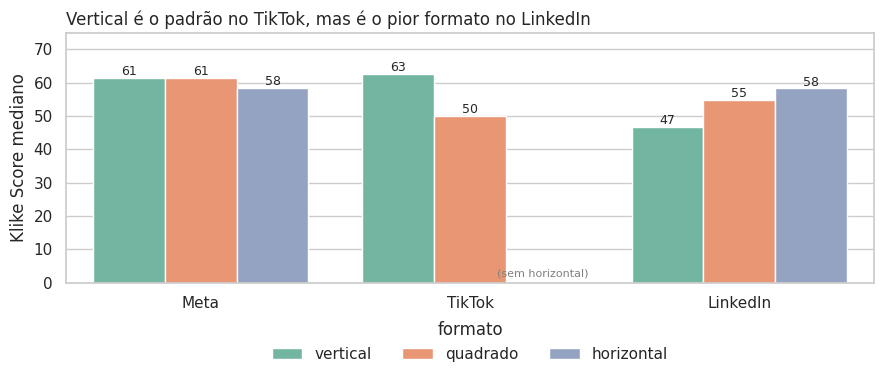

In [27]:
# Fig 5: formato por plataforma
fm = df.groupby(["platform", "format"]).agg(score=("klike_score", "median"), n=("klike_score", "size")).reset_index()
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=fm, x="platform", y="score", hue="format", hue_order=["vertical", "quadrado", "horizontal"], order=PLATFORMS,
            palette="Set2", ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f", fontsize=9)
ax.set(xlabel="", ylabel="Klike Score mediano", ylim=(0, 75))
ax.legend(title="formato", loc="upper center", bbox_to_anchor=(.5, -.1), ncol=3, frameon=False)
ax.set_title("Vertical é o padrão no TikTok, mas é o pior formato no LinkedIn", loc="left", fontsize=12)
ax.text(1.27, 2, "(sem horizontal)", fontsize=8, color="gray", ha="center")
plt.tight_layout()
fig.savefig(FIGURES_EDA / "05_formato_por_plataforma.png", dpi=150, bbox_inches="tight")

**📊 Como ler:** Klike Score mediano por plataforma e formato do vídeo. O número sobre cada barra é a mediana.

**O que o gráfico mostra**
- **Meta:** formato quase não importa (61 / 61 / 58).
- **TikTok:** vertical tem score **63** contra **50** do quadrado (−13 pontos). Não há campanhas horizontais.
- **LinkedIn:** a ordem se inverte. Horizontal tem **58**, quadrado 55 e vertical só **47**.

**💡 Takeaway:** o formato precisa seguir a plataforma. **Reaproveitar um vídeo vertical do TikTok no LinkedIn custa ~11 pontos de score**, e é uma recomendação concreta e barata (reenquadrar o vídeo). Ressalva: há só 11 campanhas verticais no LinkedIn, então esse número é o menos preciso do gráfico.

## 5. Resumo

1. **Prenda nos 3 primeiros segundos.** Hook é a alavanca mais forte em todas as plataformas (+50–70% de CTR; score mediano de 70 contra 52 sem hook).
2. **Coloque pessoas no vídeo**, especialmente para públicos de 18–34 anos. No TikTok isso vira clique; no Meta, interação.
3. **Menos texto na tela.** O nível "high" corta o CTR pela metade no Meta e tira ~16 pts do score. "Medium" é o ponto ideal.
4. **Respeite o formato nativo.** Vertical no TikTok, e horizontal ou quadrado no LinkedIn.
5. **Boas práticas se somam**: cada elemento a mais (hook, rosto, CTA, legenda) adiciona ~10 pontos ao Klike Score.
6. **A duração importa menos do que se imagina** nestes dados. Há indícios de que vídeos curtos (≤15s) funcionam melhor no Meta e de que vídeos >30s perdem CTR, mas o sinal é fraco e vale um teste A/B.

**Limitações.** São associações observacionais em 500 campanhas simuladas, não efeitos causais. O LinkedIn tem amostra pequena. Os tetos de CTR e engajamento subestimam ganhos no topo. Essas ressalvas são carregadas para a engine de recomendações, que mostra o tamanho da amostra em cada sugestão.